# Oppgave 3 – Chl-a-gradient langs et transekt (HYPSO-2 vs. Sentinel-3 OLCI)

Steg:
1. Les inn og masker `chlor_a(oci)` (samme som i oppgave 2, via `felles.py`)
2. Definer et transekt fra turbid kystvann (Po-plumen) ut mot klarere vann
3. Hent Chl-a i nærmeste piksel langs transektet for begge sensorene
4. Vis transektet på kartet, og plott Chl-a mot lengdegrad

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning, module="shapely")  # ufarlige cartopy-advarsler

import felles  # egne funksjoner: innlesing, maskering, beskjæring, transekt

# Felles fargeskala for Chl-a [mg m^-3] (samme som i oppgave 2)
VMIN, VMAX = 0.1, 30

## 1. Les inn og masker data

In [2]:
lat_h2, lon_h2, chl_h2, flagg_h2 = felles.les_produkt(felles.FIL_H2, "chlor_a(oci)")
lat_s3, lon_s3, chl_s3, flagg_s3 = felles.les_produkt(felles.FIL_S3, "chlor_a(oci)")

# Fjern land, sky, flaggede piksler og ekstreme verdier
chl_h2 = felles.masker(chl_h2, flagg_h2)
chl_s3 = felles.masker(chl_s3, flagg_s3)

# Beskjær Sentinel-3 til HYPSO-2-omrisset
kant_lon, kant_lat = felles.hypso_omriss(lat_h2, lon_h2)
lat_s3, lon_s3, chl_s3 = felles.beskjaer_til_hypso(lat_s3, lon_s3, chl_s3, kant_lon, kant_lat)

## 2. Definer transektet

Start- og sluttpunkt ligger i `felles.py` (`TRANSEKT_START`, `TRANSEKT_SLUTT`), slik at oppgave 5 bruker samme linje.
Transektet går fra Po-plumen ved kysten sør for deltaet og østover mot klarere vann i midten av Adriaterhavet.
Det går hovedsakelig øst–vest, så vi bruker **lengdegrad** på x-aksen.

Punktene ligger med 150 m avstand (omtrent HYPSO-2 sin fineste pikselstørrelse).

In [3]:
t_lat, t_lon, t_km = felles.transekt_punkter()
print(f"Start: {t_lat[0]:.2f}°N {t_lon[0]:.2f}°E   Slutt: {t_lat[-1]:.2f}°N {t_lon[-1]:.2f}°E")
print(f"Lengde: {t_km[-1]:.1f} km, {t_km.size} punkter")

Start: 44.60°N 12.35°E   Slutt: 44.45°N 13.45°E
Lengde: 89.0 km, 594 punkter


## 3. Hent Chl-a langs transektet

For hvert punkt bruker vi verdien i **nærmeste piksel** (nearest neighbour, avstand målt i meter i UTM 33N).
Hvis nærmeste piksel ligger for langt unna, blir punktet NaN.
Grensen er ca. halve pikselstørrelsen pluss litt margin:
- HYPSO-2: pikslene er ca. 140 m × 900 m, så grensen er 600 m
- Sentinel-3 OLCI: pikslene er ca. 300 m × 300 m, så grensen er 300 m

Vi lager også en **glattet kurve** (glidende median over ca. 1,5 km) som gjør trenden lettere å se gjennom pikselstøyen.

In [4]:
tr_h2 = felles.hent_langs_transekt(lat_h2, lon_h2, chl_h2, t_lat, t_lon, maks_avstand_m=600)
tr_s3 = felles.hent_langs_transekt(lat_s3, lon_s3, chl_s3, t_lat, t_lon, maks_avstand_m=300)

def glidende_median(y, vindu=11):
    """Glidende median som tåler NaN (vindu = antall punkter, 11 x 150 m ≈ 1,5 km)."""
    halv = vindu // 2
    ut = np.full_like(y, np.nan)
    for i in range(y.size):
        biter = y[max(0, i - halv): i + halv + 1]
        if np.isfinite(biter).sum() >= halv:     # krever at minst halve vinduet har data
            ut[i] = np.nanmedian(biter)
    return ut

glatt_h2 = glidende_median(tr_h2)
glatt_s3 = glidende_median(tr_s3)

print(f"Gyldige punkter: HYPSO-2 {np.isfinite(tr_h2).sum()}/{tr_h2.size},  "
      f"Sentinel-3 {np.isfinite(tr_s3).sum()}/{tr_s3.size}")

Gyldige punkter: HYPSO-2 575/594,  Sentinel-3 571/594


## 4a. Transektet tegnet inn på Chl-a-kartene

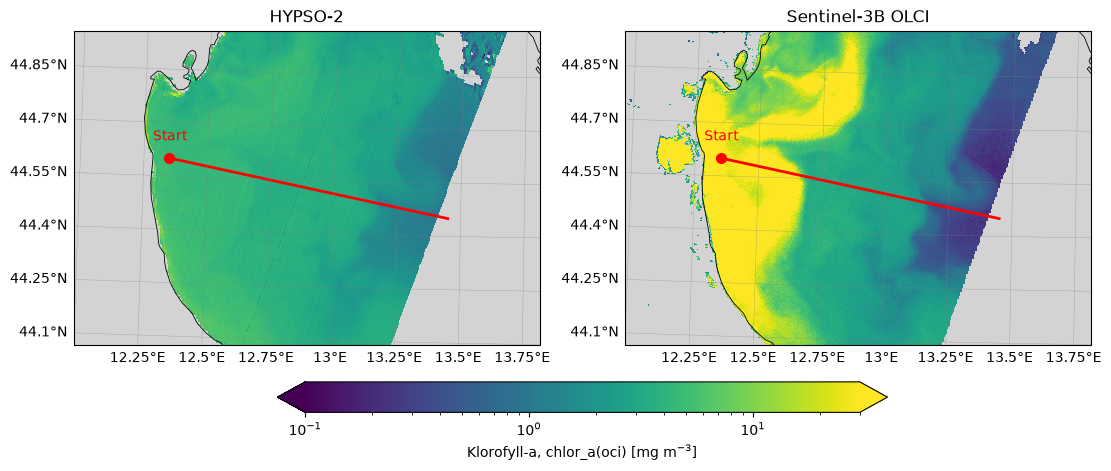

In [5]:
proj = ccrs.UTM(zone=33)
data_crs = ccrs.PlateCarree()
norm = LogNorm(vmin=VMIN, vmax=VMAX)

# Zoom inn rundt transektet
marg = 0.35
utsnitt = [t_lon.min() - marg, t_lon.max() + marg, t_lat.min() - marg, t_lat.max() + marg]

fig, akser = plt.subplots(1, 2, figsize=(11, 4.8), subplot_kw={"projection": proj},
                          constrained_layout=True)

for ax, lon, lat, chl, tittel in [
    (akser[0], lon_h2, lat_h2, chl_h2, "HYPSO-2"),
    (akser[1], lon_s3, lat_s3, chl_s3, "Sentinel-3B OLCI"),
]:
    bilde = ax.pcolormesh(lon, lat, chl, transform=data_crs, norm=norm,
                          cmap="viridis", shading="auto")
    ax.plot(t_lon, t_lat, transform=data_crs, color="red", lw=2)                        # transektet
    ax.plot(t_lon[0], t_lat[0], "o", transform=data_crs, color="red", ms=7)             # start (kyst)
    ax.text(t_lon[0], t_lat[0] + 0.05, "Start", transform=data_crs, color="red", ha="center")
    ax.set_facecolor("lightgray")  # grått = ingen data
    ax.add_feature(cfeature.COASTLINE.with_scale("10m"), linewidth=0.6)
    ax.set_extent(utsnitt, crs=data_crs)
    gl = ax.gridlines(draw_labels=True, linewidth=0.3, color="gray", alpha=0.6)
    gl.top_labels = gl.right_labels = False
    ax.set_title(tittel)

cbar = fig.colorbar(bilde, ax=akser, orientation="horizontal", shrink=0.6, pad=0.04, extend="both")
cbar.set_label("Klorofyll-a, chlor_a(oci) [mg m$^{-3}$]")
fig.savefig("oppgave3_transekt_kart.png", dpi=200, bbox_inches="tight")
plt.show()

## 4b. Chl-a langs transektet

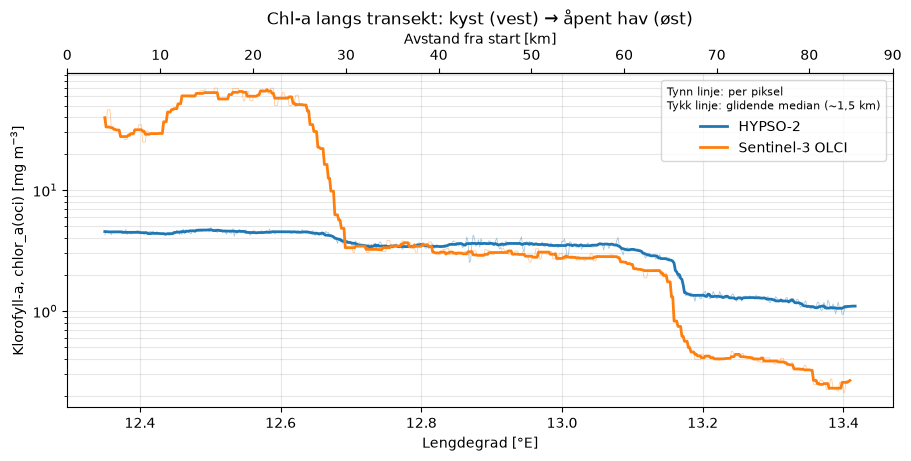

In [6]:
farge_h2, farge_s3 = "tab:blue", "tab:orange"

fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)

# Rådata (tynne, gjennomsiktige) + glattet kurve (tykk)
ax.plot(t_lon, tr_h2, color=farge_h2, lw=0.6, alpha=0.4)
ax.plot(t_lon, tr_s3, color=farge_s3, lw=0.6, alpha=0.4)
ax.plot(t_lon, glatt_h2, color=farge_h2, lw=2, label="HYPSO-2")
ax.plot(t_lon, glatt_s3, color=farge_s3, lw=2, label="Sentinel-3 OLCI")

ax.set_yscale("log")
ax.set_xlabel("Lengdegrad [°E]")
ax.set_ylabel("Klorofyll-a, chlor_a(oci) [mg m$^{-3}$]")
ax.set_title("Chl-a langs transekt: kyst (vest) → åpent hav (øst)")
ax.grid(True, which="both", alpha=0.3)
ax.legend(title="Tynn linje: per piksel\nTykk linje: glidende median (~1,5 km)", title_fontsize=8)

# Ekstra x-akse øverst med avstand fra start
topp = ax.secondary_xaxis("top", functions=(
    lambda lon: np.interp(lon, t_lon, t_km), lambda km: np.interp(km, t_km, t_lon)))
topp.set_xlabel("Avstand fra start [km]")

fig.savefig("oppgave3_transekt_chla.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Tall til tolkningen

In [7]:
# Sammenlign kyst-delen og havdelen av transektet (første og siste 20 km)
for navn, tr in [("HYPSO-2", tr_h2), ("Sentinel-3", tr_s3)]:
    kyst = np.nanmedian(tr[t_km <= 20])
    hav = np.nanmedian(tr[t_km >= t_km[-1] - 20])
    print(f"{navn:11s} kyst (0–20 km): {kyst:6.2f}   hav (siste 20 km): {hav:5.2f} mg m^-3   "
          f"forhold kyst/hav: {kyst / hav:4.1f}")

# Forhold mellom sensorene der begge har data
begge = np.isfinite(tr_h2) & np.isfinite(tr_s3)
print(f"\nMedian forhold HYPSO-2 / Sentinel-3 langs transektet: {np.median(tr_h2[begge] / tr_s3[begge]):.2f}")
print(f"Korrelasjon (log10 Chl-a): {np.corrcoef(np.log10(tr_h2[begge]), np.log10(tr_s3[begge]))[0, 1]:.2f}")

HYPSO-2     kyst (0–20 km):   4.51   hav (siste 20 km):  1.23 mg m^-3   forhold kyst/hav:  3.6
Sentinel-3  kyst (0–20 km):  55.60   hav (siste 20 km):  0.38 mg m^-3   forhold kyst/hav: 146.5

Median forhold HYPSO-2 / Sentinel-3 langs transektet: 1.14
Korrelasjon (log10 Chl-a): 0.88


## 6. Hvorfor er sensorene ulike? Rrs i tre punkter på transektet

OCI-algoritmen bruker forholdet mellom blå og grønn Rrs: MBR = max(Rrs443, Rrs490, Rrs510) / Rrs560.
Lav MBR gir høy Chl-a. Vi sammenligner Rrs og MBR for begge sensorene i plumen, midt på transektet og i klart vann.

In [8]:
import h5py

punkter = {"Plume": (44.58, 12.50), "Midt": (44.52, 12.90), "Klart vann": (44.46, 13.38)}  # (lat, lon) på transektet
baand_h2 = ["Rrs_443nm", "Rrs_492nm", "Rrs_509nm", "Rrs_561nm", "Rrs_665nm"]  # nærmeste HYPSO-bånd
baand_s3 = ["Rrs_443nm", "Rrs_490nm", "Rrs_510nm", "Rrs_560nm", "Rrs_665nm"]

def rrs_i_punkter(fil, baand, maks_avstand_m):
    """Henter Rrs (nærmeste piksel) for hvert bånd i hvert punkt."""
    with h5py.File(fil, "r") as f:
        lat, lon = f["Latitude"][:], f["Longitude"][:]
        p_lat = np.array([p[0] for p in punkter.values()])
        p_lon = np.array([p[1] for p in punkter.values()])
        return np.array([felles.hent_langs_transekt(lat, lon, f["Rrs/" + b][:], p_lat, p_lon, maks_avstand_m)
                         for b in baand]).T   # rad = punkt, kolonne = bånd

rrs_h2 = rrs_i_punkter(felles.FIL_H2, baand_h2, 600)
rrs_s3 = rrs_i_punkter(felles.FIL_S3, baand_s3, 300)

print("Rrs [10^-3 sr^-1] ved ~443 / 490 / 510 / 560 / 665 nm\n")
for i, navn in enumerate(punkter):
    for sensor, r in [("HYPSO-2", rrs_h2[i]), ("OLCI", rrs_s3[i])]:
        mbr = r[:3].max() / r[3]
        print(f"{navn:11s} {sensor:8s} " + "  ".join(f"{v * 1e3:5.2f}" for v in r) + f"   MBR = {mbr:.2f}")
    print()

Rrs [10^-3 sr^-1] ved ~443 / 490 / 510 / 560 / 665 nm

Plume       HYPSO-2   9.04  12.73  14.35  18.40   6.37   MBR = 0.78
Plume       OLCI      0.93   2.55   4.01   9.72   2.43   MBR = 0.41

Midt        HYPSO-2   5.53   8.60   9.94  11.72   2.83   MBR = 0.85
Midt        OLCI      2.32   3.73   4.20   4.67   0.95   MBR = 0.90

Klart vann  HYPSO-2   3.07   4.31   4.11   3.44   0.49   MBR = 1.25
Klart vann  OLCI      5.61   5.18   3.44   1.80   0.17   MBR = 3.12



## Answers for the report (Task 3)

The 89 km transect runs from the Po plume near the coast (44.60°N, 12.35°E) east-south-east to clearer water (44.45°N, 13.45°E).
Chl-a was sampled every 150 m from the nearest valid pixel.

**Does Chl-a decrease offshore?** Yes, for both sensors.
The decrease happens in steps separated by sharp fronts rather than as a smooth gradient.
The plume extends to about 12.7°E, and transition water with about 3 mg m⁻³ follows, where the two sensors agree well.
At 13.15°E both sensors show a sharp drop at the same position, marking the front towards central Adriatic water.
The coast/offshore ratio (first vs. last 20 km) is about 4 for HYPSO-2 and about 150 for OLCI.
The pattern reflects the nutrient-rich, buoyant Po plume, which is bounded by fronts instead of mixing gradually.

**Differences between the sensors.** The position of the fronts and the values in the transition zone agree well (r = 0.88 for log₁₀ Chl-a).
The magnitude at the two ends differs: HYPSO-2 is about 10× lower than OLCI in the plume (4.5 vs. 56 mg m⁻³) and about 3× higher in clear water (1.2 vs. 0.4 mg m⁻³).
The Rrs values in section 6 explain this.
- In the plume, OLCI Rrs(443) is very low, so the blue/green ratio is low (0.41) and Chl-a high. HYPSO-2 Rrs is elevated at all wavelengths, giving a ratio of 0.78.
- In clear water, OLCI has a typical blue-water spectrum (ratio 3.1), whereas HYPSO-2 is flatter (ratio 1.25).

The sensors see the same water masses, but HYPSO-2's band ratio, and thus its Chl-a, varies over a narrower range.
This is most likely due to calibration, atmospheric correction and signal-to-noise limitations in the blue.
The OLCI plume values are probably overestimated, because OCI interprets CDOM and sediment absorption as chlorophyll.
The 1.5 h time difference cannot explain a systematic factor of 3–10.
Without in-situ data it is not possible to say which sensor is closer to the true Chl-a.

**References**
- O'Reilly, J. E., et al. (1998). Ocean color chlorophyll algorithms for SeaWiFS. *J. Geophys. Res.*, 103(C11), 24937–24953.
- Hu, C., Lee, Z., & Franz, B. (2012). Chlorophyll a algorithms for oligotrophic oceans: A novel approach based on three-band reflectance difference. *J. Geophys. Res.*, 117, C01011.
- Fan, Y., et al. (2021). OC-SMART: A machine learning based data analysis platform for satellite ocean color sensors. *Remote Sens. Environ.*, 253, 112236.